# TechStore — First Week Report

Initial SQL report on TechStore's products, stock levels, customer base, orders, and sales targets, followed by a deeper breakdown using `JOIN`s, aggregations, and charts.  
The sample database is loaded locally into DuckDB from `SQL/seed_techstore.sql`.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect()
con.execute(Path("SQL/seed_techstore.sql").read_text(encoding="utf-8"))

DOCS_DIR = Path("docs")
DOCS_DIR.mkdir(exist_ok=True)


def sql(query: str):
    """Run a SQL query against the in-memory TechStore database and return a DataFrame."""
    return con.sql(query).df()


sql("SHOW TABLES")

,name
0,clientes
1,itens_pedido
2,pedidos
3,produtos
4,vendedores


## 1. Product Catalog

List all products ordered by category (`categoria`) and price (`preco`, highest first). Show `nome`, `categoria`, `preco`, and `estoque`.

In [2]:
query = """
SELECT nome, categoria, preco, estoque
FROM produtos
ORDER BY categoria ASC, preco DESC;
"""
sql(query)

,nome,categoria,preco,estoque
0,Teclado Mecanico Pro,Acessorios,349.9,150
1,Mouse Gamer RGB,Acessorios,189.9,300
2,Adaptador USB-C Hub,Acessorios,149.9,200
3,Suporte Notebook Aluminio,Acessorios,129.9,85
4,Cabo HDMI 2.1,Acessorios,59.9,95
5,Mousepad Gamer XL,Acessorios,49.9,110
6,"Pelicula Tablet 10""",Acessorios,39.9,150
7,"Capa Notebook 15""",Acessorios,29.9,120
8,"Monitor UltraWide 34""",Monitores,2899.0,5
9,"Monitor Gamer 27"" 144Hz",Monitores,1799.0,22


**Note:** `Notebooks` has the highest-priced items (up to R$ 7,899.00 for the `Notebook Gamer Z5`), while `Acessorios` has the widest variety (8 SKUs) and the highest inventory counts (85–300 units per item).

## 2. Low Stock Items

Find products with fewer than 15 units in stock (`estoque < 15`), ordered from lowest to highest stock. Show `nome`, `categoria`, `estoque`, and `preco`.

In [3]:
query = """
SELECT nome, categoria, estoque, preco
FROM produtos
WHERE estoque < 15
ORDER BY estoque ASC;
"""
sql(query)

,nome,categoria,estoque,preco
0,"Monitor UltraWide 34""",Monitores,5,2899.0
1,Notebook Gamer Z5,Notebooks,8,7899.0
2,Workstation W3,Notebooks,12,2599.0


**Note:** Only 3 products fall below 15 units (`Monitor UltraWide 34"` with 5, `Notebook Gamer Z5` with 8, and `Workstation W3` with 12), but all three are high-ticket items (R$ 2,599–R$ 7,899). Running out of stock on these hits revenue much harder than running low on accessories, so they should be first in line for restocking.

## 3. Customer Base by State

List all customers ordered by state (`estado`) and name (`nome`). Show `nome`, `cidade`, `estado`, and `segmento`.

In [4]:
query = """
SELECT nome, cidade, estado, segmento
FROM clientes
ORDER BY estado ASC, nome ASC;
"""
sql(query)

,nome,cidade,estado,segmento
0,Prefeitura Regional AM,Manaus,AM,governo
1,Roberto Dias,Manaus,AM,varejo
2,ComTech BA,Salvador,BA,corporativo
3,Roberto Alves,Salvador,BA,varejo
4,Secretaria de Educacao BA,Salvador,BA,governo
5,Beatriz Nogueira,Fortaleza,CE,varejo
6,StartUp XYZ,Brasilia,DF,corporativo
7,Carla Mendonca,Goiania,GO,varejo
8,Ana Oliveira,Belo Horizonte,MG,varejo
9,Camila Santos,Juiz de Fora,MG,varejo


**Note:** Most of the 47 customers are concentrated in the Southeast (`SP`, `RJ`, `MG`), with smaller pockets in the South (`PR`, `RS`, `SC`) and Northeast (`PE`, `BA`, `CE`), and very few accounts in the North and Center-West.

## 4. Government Segment Customers

List customers in the `governo` segment, ordered alphabetically by `nome`. Show `nome`, `cidade`, `estado`, and `segmento`.

In [5]:
query = """
SELECT nome, cidade, estado, segmento
FROM clientes
WHERE segmento = 'governo'
ORDER BY nome ASC;
"""
sql(query)

,nome,cidade,estado,segmento
0,Governo MG Edu,Belo Horizonte,MG,governo
1,Governo RJ Digital,Rio de Janeiro,RJ,governo
2,Prefeitura Regional AM,Manaus,AM,governo
3,Prefeitura de Recife,Recife,PE,governo
4,Recife Digital,Recife,PE,governo
5,Secretaria de Educacao BA,Salvador,BA,governo
6,TechGov SP,Sao Paulo,SP,governo


**Note:** There are 7 government accounts spread across 6 states (`AM`, `BA`, `MG`, `PE`, `RJ`, `SP`). Because public-sector procurement usually involves tenders and longer approval cycles, tracking these separately from retail accounts makes sense for forecasting.

## 5. Top 10 Orders by Value

List the 10 largest orders by `valor_total`. Show `id`, `data_pedido`, `valor_total`, `status`, and `forma_pagamento`.

In [6]:
query = """
SELECT id, data_pedido, valor_total, status, forma_pagamento
FROM pedidos
ORDER BY valor_total DESC
LIMIT 10;
"""
sql(query)

,id,data_pedido,valor_total,status,forma_pagamento
0,34,2024-02-20,12450.0,entregue,cartao
1,67,2024-03-05,8799.9,entregue,pix
2,91,2024-03-11,8799.0,pendente,cartao
3,4,2023-12-04,7899.0,entregue,cartao
4,12,2024-01-18,7899.0,entregue,cartao
5,44,2024-02-09,7899.0,entregue,cartao
6,52,2024-02-20,7899.0,entregue,cartao
7,94,2024-03-12,7899.0,entregue,cartao
8,155,2024-03-09,6480.0,pendente,cartao
9,41,2024-02-02,5480.0,cancelado,cartao


**Note:** The largest order is `#34` (R$ 12,450.00, paid by card, delivered). Worth flagging: two of the top 10 orders (`#91` at R$ 8,799.00 and `#155` at R$ 6,480.00) are still `pendente`, and `#41` (R$ 5,480.00) was `cancelado`.

## 6. Cancelled Orders

List all orders with `status = 'cancelado'`, ordered from highest to lowest `valor_total`. Show `id`, `data_pedido`, `valor_total`, and `forma_pagamento`.

In [7]:
query = """
SELECT id, data_pedido, valor_total, forma_pagamento
FROM pedidos
WHERE status = 'cancelado'
ORDER BY valor_total DESC;
"""
sql(query)

,id,data_pedido,valor_total,forma_pagamento
0,41,2024-02-02,5480.0,cartao
1,132,2024-01-17,4599.0,cartao
2,136,2024-03-10,4599.0,cartao
3,15,2024-01-10,3299.0,boleto
4,133,2024-01-20,2583.1,pix
5,73,2024-03-08,2199.0,pix
6,29,2024-01-25,1899.0,cartao
7,137,2024-03-12,1899.0,cartao
8,138,2024-03-14,1163.0,boleto
9,23,2024-01-15,899.9,boleto


**Note:** There are 12 cancelled orders totaling R$ 28,940.00. Card payments (`cartao`) account for 5 of them and 63.8% of the cancelled value (R$ 18,476.00), including the three largest cancellations (`#41`, `#136`, `#132`).

## 7. Sales Reps Above R$ 50,000 Target

List sales reps with a monthly target (`meta_mensal`) above R$ 50,000, ordered from highest to lowest target. Show `nome`, `regiao`, and `meta_mensal`.

In [8]:
query = """
SELECT nome, regiao, meta_mensal
FROM vendedores
WHERE meta_mensal > 50000
ORDER BY meta_mensal DESC;
"""
sql(query)

,nome,regiao,meta_mensal
0,Ricardo Mendes,Sudeste,60000.0
1,Carlos Eduardo,Sudeste,55000.0


**Note:** Only 2 of the 7 sales reps have targets above R$ 50,000 — `Ricardo Mendes` (R$ 60,000) and `Carlos Eduardo` (R$ 55,000). Both cover `Sudeste`, which lines up with where most of the customer base is located.

---

# Deeper Analysis (`JOIN`s & Aggregations)

Beyond the initial 7 queries, the cells below combine tables to look at rep performance, cancellation rates, category margins, and dead stock.

## 8. Delivered Revenue by Sales Rep

Compare each rep's delivered orders and total revenue (Dec 2023 – Mar 2024, 4 calendar months) against their stated `meta_mensal`.

In [9]:
query = """
SELECT
    v.nome,
    v.regiao,
    v.meta_mensal,
    COUNT(p.id) AS pedidos_entregues,
    ROUND(SUM(p.valor_total), 2) AS faturamento_total,
    ROUND(SUM(p.valor_total) / 4.0, 2) AS media_mensal,
    ROUND(100.0 * (SUM(p.valor_total) / 4.0) / v.meta_mensal, 1) AS pct_meta_mensal
FROM vendedores v
LEFT JOIN pedidos p
    ON p.vendedor_id = v.id AND p.status = 'entregue'
GROUP BY v.id, v.nome, v.regiao, v.meta_mensal
ORDER BY faturamento_total DESC;
"""
df_reps = sql(query)
df_reps

,nome,regiao,meta_mensal,pedidos_entregues,faturamento_total,media_mensal,pct_meta_mensal
0,Ricardo Mendes,Sudeste,60000.0,26,69300.3,17325.08,28.9
1,Fernanda Lima,Sul,45000.0,21,61382.6,15345.65,34.1
2,Juliana Rocha,Nordeste,40000.0,20,59480.0,14870.00,37.2
3,Carlos Eduardo,Sudeste,55000.0,19,53233.7,13308.42,24.2
4,Marcos Santana,Nordeste,35000.0,19,48881.9,12220.48,34.9
5,Amanda Torres,Norte,30000.0,8,19329.0,4832.25,16.1
6,Bruno Alves,Centro-Oeste,35000.0,8,14682.9,3670.72,10.5


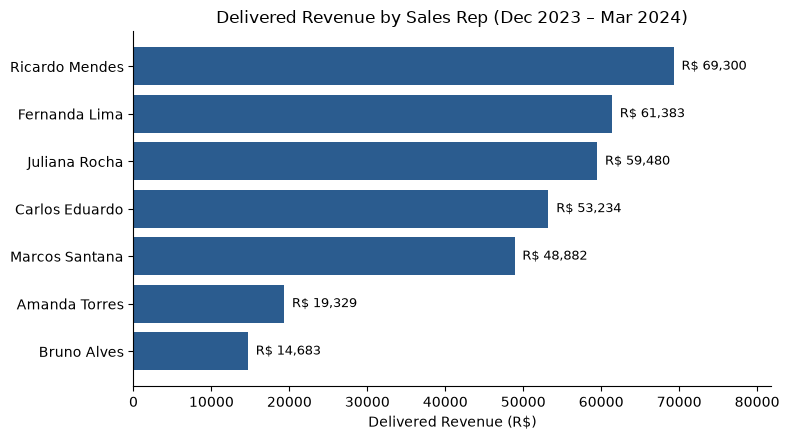

In [10]:
plot_df = df_reps.sort_values("faturamento_total", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(plot_df["nome"], plot_df["faturamento_total"], color="#2b5c8f")
ax.set_xlabel("Delivered Revenue (R$)")
ax.set_title("Delivered Revenue by Sales Rep (Dec 2023 – Mar 2024)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(0, plot_df["faturamento_total"].max() * 1.18)

for bar, val in zip(bars, plot_df["faturamento_total"]):
    ax.text(val + 1000, bar.get_y() + bar.get_height() / 2, f"R$ {val:,.0f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(DOCS_DIR / "revenue_by_rep.png", dpi=150)
plt.show()

**Note:** `Ricardo Mendes` leads in total delivered revenue (R$ 69,300.30 across 26 orders), followed by `Fernanda Lima` (R$ 61,382.60) and `Juliana Rocha` (R$ 59,480.00). On a monthly average, no rep reaches 40% of `meta_mensal` — either the targets are set well above current demand, or they were intended as quarterly targets rather than monthly ones.

## 9. Cancellation Rate by Payment Method

Compare cancelled order counts, cancellation rate, and cancelled revenue across `cartao`, `boleto`, and `pix`.

In [11]:
query = """
SELECT
    forma_pagamento,
    COUNT(*) AS total_pedidos,
    COUNT(*) FILTER (WHERE status = 'cancelado') AS cancelados,
    ROUND(100.0 * COUNT(*) FILTER (WHERE status = 'cancelado') / COUNT(*), 1) AS taxa_cancelamento_pct,
    ROUND(COALESCE(SUM(valor_total) FILTER (WHERE status = 'cancelado'), 0), 2) AS valor_cancelado
FROM pedidos
GROUP BY forma_pagamento
ORDER BY valor_cancelado DESC;
"""
df_cancel = sql(query)
df_cancel

,forma_pagamento,total_pedidos,cancelados,taxa_cancelamento_pct,valor_cancelado
0,cartao,85,5,5.9,18476.0
1,boleto,24,4,16.7,5492.0
2,pix,57,3,5.3,4972.0


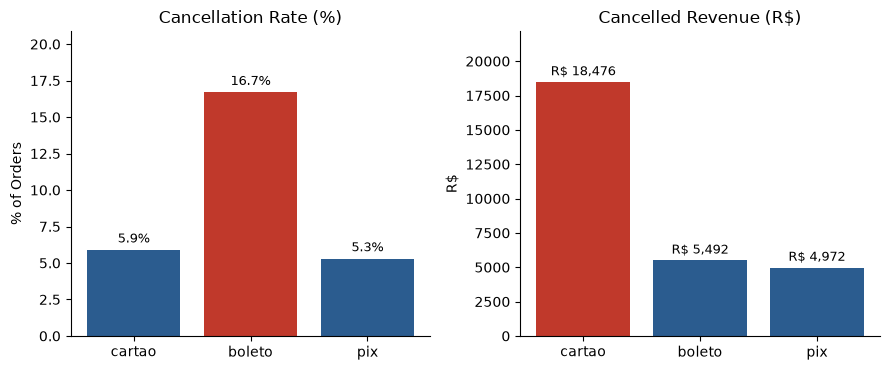

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))

ax1.bar(df_cancel["forma_pagamento"], df_cancel["taxa_cancelamento_pct"], color=["#2b5c8f", "#c0392b", "#2b5c8f"])
ax1.set_title("Cancellation Rate (%)")
ax1.set_ylabel("% of Orders")
ax1.set_ylim(0, df_cancel["taxa_cancelamento_pct"].max() * 1.25)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
for i, val in enumerate(df_cancel["taxa_cancelamento_pct"]):
    ax1.text(i, val + 0.5, f"{val:.1f}%", ha="center", fontsize=9)

ax2.bar(df_cancel["forma_pagamento"], df_cancel["valor_cancelado"], color=["#c0392b", "#2b5c8f", "#2b5c8f"])
ax2.set_title("Cancelled Revenue (R$)")
ax2.set_ylabel("R$")
ax2.set_ylim(0, df_cancel["valor_cancelado"].max() * 1.2)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
for i, val in enumerate(df_cancel["valor_cancelado"]):
    ax2.text(i, val + 500, f"R$ {val:,.0f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(DOCS_DIR / "cancellations_by_payment.png", dpi=150)
plt.show()

**Note:** Looking at volume and value separately tells two different stories: `cartao` represents the most lost revenue (R$ 18,476.00) because ticket sizes are larger, but `boleto` has by far the highest cancellation rate at **16.7%** (4 out of 24 orders) — roughly 3x the rate of `cartao` (5.9%) and `pix` (5.3%). Unpaid `boleto` expirations are a common pattern in Brazilian e-commerce.

## 10. Gross Margin and Stock Value by Category

Calculate average gross margin (`(preco - custo) / preco`) and retail inventory value (`preco * estoque`) per product category.

In [13]:
query = """
SELECT
    categoria,
    COUNT(*) AS skus,
    ROUND(AVG((preco - custo) / preco * 100), 1) AS margem_media_pct,
    SUM(estoque) AS unidades_estoque,
    ROUND(SUM(preco * estoque), 2) AS valor_estoque_venda
FROM produtos
GROUP BY categoria
ORDER BY margem_media_pct DESC;
"""
sql(query)

,categoria,skus,margem_media_pct,unidades_estoque,valor_estoque_venda
0,Acessorios,8,56.4,1210.0,171229.0
1,Monitores,3,38.5,92.0,112508.0
2,Smartphones,4,36.6,445.0,779055.0
3,Tablets,3,36.3,135.0,249365.0
4,Notebooks,5,34.6,128.0,491253.0


**Note:** `Acessorios` carries the highest average gross margin (56.4%), while `Notebooks` has the lowest (34.6%). Most of the capital tied up in inventory sits in `Smartphones` (R$ 779,055.00) and `Notebooks` (R$ 491,253.00).

## 11. Products With Zero Sales

Use a `LEFT JOIN` to find catalog products that have never appeared in `itens_pedido`.

In [14]:
query = """
SELECT
    p.nome,
    p.categoria,
    p.preco,
    p.estoque,
    ROUND(p.preco * p.estoque, 2) AS valor_parado
FROM produtos p
LEFT JOIN itens_pedido i ON i.produto_id = p.id
WHERE i.id IS NULL
ORDER BY valor_parado DESC;
"""
sql(query)

,nome,categoria,preco,estoque,valor_parado
0,Notebook Essencial E2,Notebooks,2499.9,45,112495.5
1,"Tablet Essencial 8""",Tablets,1199.0,40,47960.0
2,Adaptador USB-C Hub,Acessorios,149.9,200,29980.0
3,Suporte Notebook Aluminio,Acessorios,129.9,85,11041.5
4,"Pelicula Tablet 10""",Acessorios,39.9,150,5985.0


**Note:** 5 of the 23 catalog products have zero recorded orders. Two of them — `Notebook Essencial E2` (45 units, R$ 112,495.50) and `Tablet Essencial 8"` (40 units, R$ 47,960.00) — account for over R$ 160,000 in unsold inventory value and are worth reviewing for pricing or bundling.